# RF-DETR Weighted Boxes Fusion ensemble

Models: **RF-DETR dropout 0.1**, **erasing 0.1 + flip**, **erasing 0.1**, **flip**, evaluated on the val and test splits.

1. Each model on its own
2. Each model with flip test-time augmentation (TTA)
3. The WBF ensemble, without and with flip TTA, compared with each individual model

Weighted Boxes Fusion (Solovyev et al., 2021), per image and per class:
- pool every model's boxes (confidence >= `SKIP_BOX_THR`) and go through them from highest to lowest confidence
- a box joins the cluster whose fused box it overlaps with IoU > `WBF_IOU`, otherwise it starts a new cluster
- each cluster's fused box is the confidence-weighted average of its boxes' coordinates
- the fused confidence is the weighted average, over all models, of each model's highest confidence in the cluster, with 0 for a model
  that has no box there. A box found by only one model therefore ends up with at most 1/4 of its confidence
  (1/8 with flip TTA, where each model contributes an original and a flipped prediction).

Flip TTA: every model also predicts on the horizontally mirrored image, and those boxes are flipped back
(x1' = W - x2, x2' = W - x1) so they line up with the original image. The original and un-flipped predictions are then
merged with WBF as if they came from separate models, for one model ("+ flip TTA") or for all models together.

Unlike majority voting, WBF uses every model's boxes. Objects found only by some models can still be detected (recall), box
coordinates are averaged (localisation, mAP75 / mAP50-95), and a class only one model predicts is pushed down in confidence.

In [44]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import supervision as sv
import torch
import yaml
from PIL import Image, ImageOps
from pathlib import Path
from supervision.metrics import MeanAveragePrecision, Precision, Recall, AveragingMethod
from rfdetr import from_checkpoint

TEXT, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'

print('CUDA available:', torch.cuda.is_available())
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

CUDA available: True
GPU: NVIDIA GeForce RTX 3070


In [45]:
PROJECT_ROOT = Path.cwd().resolve().parents[1]  # ai-applications/vs_notebooks -> repo root

DATASET_DIR = PROJECT_ROOT / 'data' / 'wildlife_dataset'
DATA = DATASET_DIR / 'wildlife_dataset.yaml'
TRAINED_MODEL_DIR = PROJECT_ROOT / 'ai-applications' / 'trained_models'
RESULTS_DIR = PROJECT_ROOT / 'ai-applications' / 'training_results' / 'rf-detr-ensemble-wbf'

MODELS = {
    'RF-DETR dropout 0.1': TRAINED_MODEL_DIR / 'rfdetr_dropout_10.pth',
    'RF-DETR erasing 0.1 + flip': TRAINED_MODEL_DIR / 'rfdetr_erasing_10_flip.pth',
    'RF-DETR erasing 0.1': TRAINED_MODEL_DIR / 'rfdetr_erasing_10.pth',
    'RF-DETR flip': TRAINED_MODEL_DIR / 'rfdetr_flip.pth',
}
MODEL_WEIGHTS = {name: 1.0 for name in MODELS}  # raise a model's weight to trust its boxes and confidences more
ENSEMBLE_NAME = 'Ensemble (WBF)'
TTA_SUFFIX = ' + flip TTA'
TTA_ENSEMBLE_NAME = ENSEMBLE_NAME[:-1] + TTA_SUFFIX + ')'  # 'Ensemble (WBF + flip TTA)'

SPLITS = ['val', 'test']
PREDICT_THRESHOLD = 0.01  # keep low-confidence boxes so mAP sees the full precision-recall curve
WBF_IOU = 0.55  # a box joins a cluster if its IoU with the cluster's fused box is above this
SKIP_BOX_THR = 0.1  # boxes below this confidence are left out of the fusion (best val mAP50-95 in the earlier sweep)
EVAL_IOU = 0.5  # IoU for precision / recall / confusion matrix (same as precision_at_50)

assert DATASET_DIR.exists(), f'Dataset not found: {DATASET_DIR}'
for path in MODELS.values():
    assert path.exists(), f'Model not found: {path}'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

with open(DATA, 'r') as f:
    names = yaml.safe_load(f)['names']
CLASS_NAMES = [names[i] for i in sorted(names)] if isinstance(names, dict) else list(names)

print('Dataset:', DATASET_DIR)
print('Results dir:', RESULTS_DIR)
print('Classes:', CLASS_NAMES)

Dataset: C:\Users\zheng\Documents\ISY5002-PRS-G14\data\wildlife_dataset
Results dir: C:\Users\zheng\Documents\ISY5002-PRS-G14\ai-applications\training_results\rf-detr-ensemble-wbf
Classes: ['buffalo', 'elephant', 'rhino', 'zebra', 'okapi', 'leopard', 'cheetah']


## Metrics

In [46]:
def evaluate(predictions, targets):
    map_result = MeanAveragePrecision().update(predictions, targets).compute()

    # Precision / recall at the confidence with the best F1 (same convention as the training notebooks)
    best = {'F1': -1.0}
    for conf in np.arange(0.05, 0.96, 0.05):
        kept = [p[p.confidence >= conf] for p in predictions]
        precision = Precision(averaging_method=AveragingMethod.MACRO).update(kept, targets).compute().precision_at_50
        recall = Recall(averaging_method=AveragingMethod.MACRO).update(kept, targets).compute().recall_at_50
        f1 = 2 * precision * recall / (precision + recall + 1e-9)
        if f1 > best['F1']:
            best = {'Precision': float(precision), 'Recall': float(recall), 'F1': float(f1), 'Confidence': round(float(conf), 2)}

    return {
        'Precision': best['Precision'],
        'Recall': best['Recall'],
        'F1': best['F1'],
        'mAP50': float(map_result.map50),
        'mAP75': float(map_result.map75),
        'mAP50-95': float(map_result.map50_95),
        'Best-F1 confidence': best['Confidence'],
    }, map_result


def per_class_ap(map_result):
    ap = pd.DataFrame(index=CLASS_NAMES, columns=['AP50', 'AP50-95'], dtype=float)
    for class_id, row in zip(map_result.matched_classes, map_result.ap_per_class):
        ap.loc[CLASS_NAMES[int(class_id)]] = [row[0], row.mean()]
    return ap


def confusion_counts(predictions, targets, conf_threshold):
    # rows = true, columns = predicted, last row/column = background
    return sv.ConfusionMatrix.from_detections(
        predictions=predictions,
        targets=targets,
        classes=CLASS_NAMES,
        conf_threshold=conf_threshold,
        iou_threshold=EVAL_IOU
    ).matrix.astype(int)


def per_class_table(counts):
    tp = np.diag(counts)[:-1]
    fp = counts[:, :-1].sum(axis=0) - tp  # predicted as the class, but the true class / background differs
    fn = counts[:-1, :].sum(axis=1) - tp  # true class predicted as another class or missed
    animals = counts[:-1, :-1]
    table = pd.DataFrame({
        'TP': tp,
        'FP': fp,
        'FN': fn,
        'Wrong class': animals.sum(axis=1) - tp,
        'Missed': counts[:-1, -1],
        'False detections': counts[-1, :-1],
    }, index=CLASS_NAMES)
    table['Precision'] = tp / np.maximum(tp + fp, 1)
    table['Recall'] = tp / np.maximum(tp + fn, 1)
    table['F1'] = 2 * table['Precision'] * table['Recall'] / (table['Precision'] + table['Recall'] + 1e-9)
    # Of the animals the model found, how many got the right label
    table['Classification accuracy'] = tp / np.maximum(tp + table['Wrong class'], 1)
    return table


def report_details(name, file_tag):
    """Per-class AP, confusion matrix (printed + plotted) and per-class P/R/F1 of one model on every split."""
    labels = CLASS_NAMES + ['background']
    fig, axes = plt.subplots(1, len(SPLITS), figsize=(7 * len(SPLITS), 6))

    for ax, split in zip(np.atleast_1d(axes), SPLITS):
        metrics, map_result = results[split][name]
        conf_threshold = metrics['Best-F1 confidence']
        counts = confusion_counts(predictions[split][name], targets[split], conf_threshold)

        print(f'\n{"=" * 30} [{split}] {name} {"=" * 30}')
        print('\nPer-class AP')
        print(per_class_ap(map_result).round(4).to_string())

        matrix = pd.DataFrame(counts, index=[f'true {l}' for l in labels], columns=[f'pred {l}' for l in labels])
        matrix.to_csv(RESULTS_DIR / f'{file_tag}_confusion_matrix_{split}.csv')
        print(f'\nConfusion matrix (conf >= {conf_threshold}, IoU {EVAL_IOU})')
        print(matrix.to_string())

        per_class = per_class_table(counts)
        per_class.to_csv(RESULTS_DIR / f'{file_tag}_confusion_per_class_{split}.csv')
        print('\nPer-class precision / recall / F1 (from the confusion matrix)')
        print(per_class.round(4).to_string())

        # Shade each true class by its share of that row; the background row has no true total, so leave it unshaded
        row_share = counts / np.maximum(counts.sum(axis=1, keepdims=True), 1)
        row_share[-1] = 0
        ax.imshow(row_share, cmap='Blues', vmin=0, vmax=1)
        for i in range(len(labels)):
            for j in range(len(labels)):
                if counts[i, j]:
                    ax.text(j, i, counts[i, j], ha='center', va='center', fontsize=11,
                            color='white' if row_share[i, j] > 0.5 else TEXT)
        ax.set_xticks(range(len(labels)), labels, rotation=30, ha='right')
        ax.set_yticks(range(len(labels)), labels)
        ax.set_xlabel('Predicted', color=MUTED)
        ax.set_ylabel('True', color=MUTED)
        ax.set_title(f'{name}: {split} (conf >= {conf_threshold}, IoU 0.5)', loc='left', fontsize=12, color=TEXT)
        ax.tick_params(colors=MUTED, length=0)
        for spine in ax.spines.values():
            spine.set_visible(False)

    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f'{file_tag}_confusion_matrix.png', dpi=150, bbox_inches='tight')
    plt.show()

## Load models and data

In [47]:
models = {}
for name, path in MODELS.items():
    models[name] = from_checkpoint(path)
    print(f'Loaded {name}: {path.name}')

datasets, targets = {}, {}
for split in SPLITS:
    datasets[split] = sv.DetectionDataset.from_yolo(
        images_directory_path=str(DATASET_DIR / 'images' / split),
        annotations_directory_path=str(DATASET_DIR / 'labels' / split),
        data_yaml_path=str(DATA)
    )
    targets[split] = [annotations for _, _, annotations in datasets[split]]
    print(f'{split}: {len(datasets[split])} images, {sum(len(t) for t in targets[split])} ground-truth boxes')

# predictions[split][model name] -> list of sv.Detections, one per image; results[split][model name] -> (metrics, map_result)
predictions = {split: {} for split in SPLITS}
results = {split: {} for split in SPLITS}

[2026-10-23 00:11:30] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-23 00:11:30] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-23 00:11:30] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-23 00:11:30] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


Loaded RF-DETR dropout 0.1: rfdetr_dropout_10.pth


[2026-10-23 00:11:30] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-23 00:11:30] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


Loaded RF-DETR erasing 0.1 + flip: rfdetr_erasing_10_flip.pth


[2026-10-23 00:11:31] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-23 00:11:31] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


Loaded RF-DETR erasing 0.1: rfdetr_erasing_10.pth
Loaded RF-DETR flip: rfdetr_flip.pth
val: 332 images, 457 ground-truth boxes
test: 331 images, 474 ground-truth boxes


## Individual models

Inference on val and test with each model, on the original image and on the horizontally mirrored image. The mirrored
predictions are flipped back into the original image's coordinates and kept in `flipped[split][model name]`.

In [48]:
def unflip(detections, width):
    """Map boxes predicted on the horizontally mirrored image back to the original image."""
    xyxy = detections.xyxy.copy()
    xyxy[:, 0], xyxy[:, 2] = width - detections.xyxy[:, 2], width - detections.xyxy[:, 0]
    detections.xyxy = xyxy
    return detections


flipped = {split: {} for split in SPLITS}  # flipped[split][model name] -> un-flipped predictions on the mirrored images
for split in SPLITS:
    image_paths = datasets[split].image_paths
    for name in MODELS:
        predictions[split][name] = []
        flipped[split][name] = []
    for n, image_path in enumerate(image_paths, 1):
        image = Image.open(image_path).convert('RGB')
        mirrored = ImageOps.mirror(image)
        for name in MODELS:
            predictions[split][name].append(models[name].predict(image, threshold=PREDICT_THRESHOLD))
            flipped[split][name].append(unflip(models[name].predict(mirrored, threshold=PREDICT_THRESHOLD), image.width))
        if n % 50 == 0 or n == len(image_paths):
            print(f'{split}: inferred {n}/{len(image_paths)} images (original + mirrored)')


[2026-10-23 00:11:33] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).
[2026-10-23 00:11:33] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).
[2026-10-23 00:11:34] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).
[2026-10-23 00:11:34] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


val: inferred 50/332 images (original + mirrored)
val: inferred 100/332 images (original + mirrored)
val: inferred 150/332 images (original + mirrored)
val: inferred 200/332 images (original + mirrored)
val: inferred 250/332 images (original + mirrored)
val: inferred 300/332 images (original + mirrored)
val: inferred 332/332 images (original + mirrored)
test: inferred 50/331 images (original + mirrored)
test: inferred 100/331 images (original + mirrored)
test: inferred 150/331 images (original + mirrored)
test: inferred 200/331 images (original + mirrored)
test: inferred 250/331 images (original + mirrored)
test: inferred 300/331 images (original + mirrored)
test: inferred 331/331 images (original + mirrored)


## Ensemble: Weighted Boxes Fusion

In [49]:
def fuse(detections_per_model, weights, skip_box_thr=SKIP_BOX_THR):
    """Weighted Boxes Fusion of one image's detections from every model.
    Returns the fused detections and, per fused box, how many models contributed to it."""
    xyxy, conf, class_id, model_idx = [], [], [], []
    for m, detections in enumerate(detections_per_model):
        keep = detections.confidence >= skip_box_thr
        xyxy.append(detections.xyxy[keep])
        conf.append(detections.confidence[keep])
        class_id.append(detections.class_id[keep])
        model_idx.append(np.full(keep.sum(), m))
    xyxy, conf, class_id, model_idx = map(np.concatenate, (xyxy, conf, class_id, model_idx))
    weights = np.asarray(weights, dtype=float)
    box_weight = conf * weights[model_idx]

    fused_xyxy, fused_conf, fused_class, n_models = [], [], [], []
    for cls in np.unique(class_id):
        order = np.flatnonzero(class_id == cls)
        order = order[np.argsort(-conf[order], kind='stable')]
        clusters, boxes = [], np.empty((0, 4))
        for i in order:
            if len(boxes):
                iou = sv.box_iou_batch(xyxy[i][None], boxes)[0]
                j = iou.argmax()
                if iou[j] > WBF_IOU:
                    clusters[j].append(i)
                    members = clusters[j]
                    boxes[j] = (box_weight[members, None] * xyxy[members]).sum(axis=0) / box_weight[members].sum()
                    continue
            clusters.append([i])
            boxes = np.vstack([boxes, xyxy[i]])

        for members, box in zip(clusters, boxes):
            # Each model's best confidence in the cluster, 0 for models without a box here
            best = np.zeros(len(weights))
            np.maximum.at(best, model_idx[members], conf[members])
            fused_xyxy.append(box)
            fused_conf.append((weights * best).sum() / weights.sum())
            fused_class.append(cls)
            n_models.append(int((best > 0).sum()))

    if not fused_xyxy:
        return sv.Detections.empty(), np.empty(0, dtype=int)
    fused = sv.Detections(xyxy=np.array(fused_xyxy), class_id=np.array(fused_class, dtype=int),
                          confidence=np.array(fused_conf))
    return fused, np.array(n_models)

## Ensemble: fusion

Fuses the predictions from above, image by image:
- `<model> + flip TTA`: one model's original and un-flipped predictions
- `Ensemble (WBF)`: every model's original predictions
- `Ensemble (WBF + flip TTA)`: every model's original and un-flipped predictions

In [50]:
MODEL_NAMES = list(MODELS)
weights = [MODEL_WEIGHTS[name] for name in MODEL_NAMES]
ensemble_support = {ENSEMBLE_NAME: {}, TTA_ENSEMBLE_NAME: {}}

for split in SPLITS:
    for name in MODEL_NAMES:
        predictions[split][name + TTA_SUFFIX] = [
            fuse([original, mirrored], [MODEL_WEIGHTS[name]] * 2)[0]
            for original, mirrored in zip(predictions[split][name], flipped[split][name])
        ]

    members = {
        ENSEMBLE_NAME: ([predictions[split][name] for name in MODEL_NAMES], weights),
        TTA_ENSEMBLE_NAME: ([predictions[split][name] for name in MODEL_NAMES] + [flipped[split][name] for name in MODEL_NAMES],
                            weights * 2),
    }
    for ensemble, (per_member, member_weights) in members.items():
        predictions[split][ensemble] = []
        ensemble_support[ensemble][split] = []
        for per_image in zip(*per_member):
            fused, support = fuse(per_image, member_weights)
            predictions[split][ensemble].append(fused)
            ensemble_support[ensemble][split].append(support)
    print(f'{split}: fused {len(predictions[split][ENSEMBLE_NAME])} images')

# Each model next to its TTA version, then the two ensembles
EVAL_NAMES = [n for name in MODEL_NAMES for n in (name, name + TTA_SUFFIX)] + [ENSEMBLE_NAME, TTA_ENSEMBLE_NAME]


val: fused 332 images
test: fused 331 images


## Ensemble: overall metrics vs each model

Precision / recall / F1 are macro-averaged at IoU 0.5 and the confidence with the best F1.

In [51]:
summary_rows = []
for split in SPLITS:
    for name in EVAL_NAMES:
        results[split][name] = evaluate(predictions[split][name], targets[split])
    comparison = pd.DataFrame({name: results[split][name][0] for name in EVAL_NAMES}).T
    summary_rows += [{'Split': split, 'Model': name, **metrics} for name, metrics in comparison.to_dict('index').items()]
    print(f'\n[{split}]')
    print(comparison.round(4).to_string())

summary = pd.DataFrame(summary_rows)
summary.to_csv(RESULTS_DIR / 'ensemble_evaluation.csv', index=False)
print('\nSaved results to:', RESULTS_DIR / 'ensemble_evaluation.csv')

# Best single model on val, to compare against the ensemble in detail
BEST_SINGLE = max(MODELS, key=lambda name: results['val'][name][0]['F1'])
print('Best single model on val (F1):', BEST_SINGLE)


[val]
                                       Precision  Recall      F1   mAP50   mAP75  mAP50-95  Best-F1 confidence
RF-DETR dropout 0.1                       0.9745  0.9584  0.9663  0.9862  0.9518    0.8885                0.65
RF-DETR dropout 0.1 + flip TTA            0.9644  0.9584  0.9614  0.9785  0.9415    0.8809                0.55
RF-DETR erasing 0.1 + flip                0.9488  0.9542  0.9515  0.9812  0.9663    0.9008                0.50
RF-DETR erasing 0.1 + flip + flip TTA     0.9792  0.9502  0.9645  0.9813  0.9386    0.8836                0.60
RF-DETR erasing 0.1                       0.9663  0.9546  0.9605  0.9845  0.9667    0.8978                0.50
RF-DETR erasing 0.1 + flip TTA            0.9711  0.9576  0.9643  0.9837  0.9485    0.8846                0.50
RF-DETR flip                              0.9716  0.9406  0.9559  0.9840  0.9643    0.9007                0.55
RF-DETR flip + flip TTA                   0.9593  0.9546  0.9569  0.9821  0.9562    0.8886               

## Best single model: per-class AP, confusion matrix, per-class precision / recall / F1

Confusion matrix at the model's best-F1 confidence and IoU 0.5.


============================== [val] RF-DETR dropout 0.1 ==============================

Per-class AP
            AP50  AP50-95
buffalo   0.9673   0.8439
elephant  0.9938   0.8800
rhino     0.9980   0.9306
zebra     0.9700   0.8457
okapi     1.0000   0.9139
leopard   0.9982   0.8976
cheetah   0.9759   0.9078

Confusion matrix (conf >= 0.65, IoU 0.5)
                 pred buffalo  pred elephant  pred rhino  pred zebra  pred okapi  pred leopard  pred cheetah  pred background
true buffalo               48              0           0           0           0             0             0                5
true elephant               0             44           0           0           0             0             0                1
true rhino                  0              0          54           0           0             0             0                2
true zebra                  0              0           0          92           0             0             0                7
true okapi       

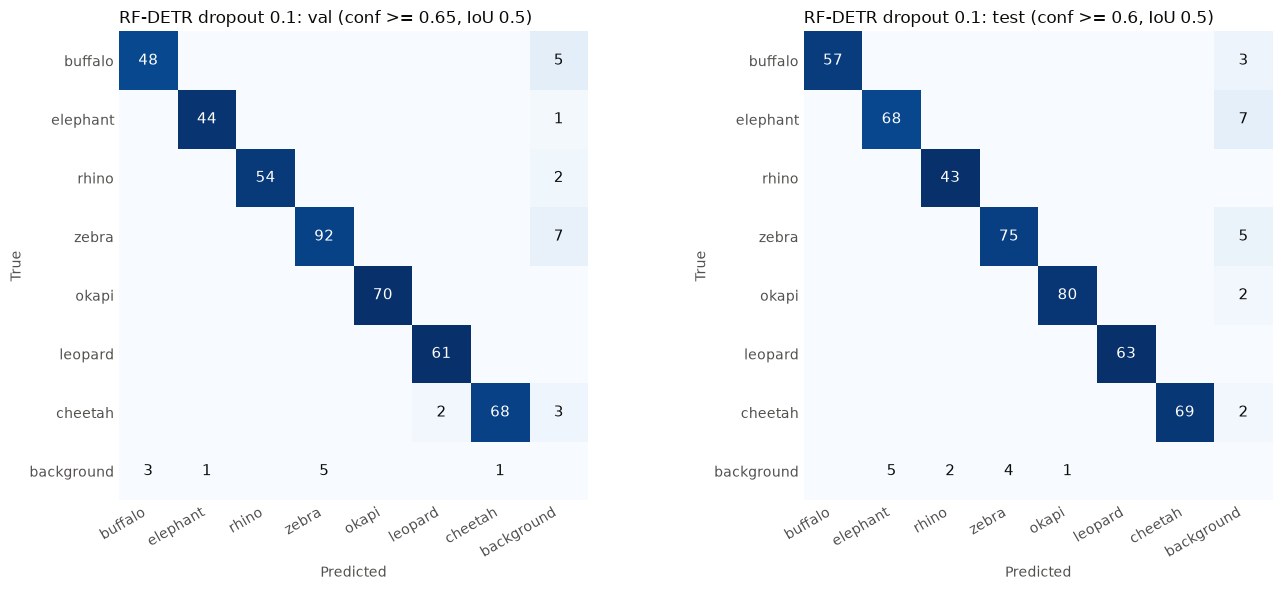

In [52]:
report_details(BEST_SINGLE, 'best_single')

## Ensemble with flip TTA: per-class AP, confusion matrix, per-class precision / recall / F1

Confusion matrix at the ensemble's best-F1 confidence and IoU 0.5.


============================== [val] Ensemble (WBF + flip TTA) ==============================

Per-class AP
            AP50  AP50-95
buffalo   0.9750   0.8665
elephant  0.9940   0.8857
rhino     0.9971   0.9369
zebra     0.9722   0.8544
okapi     1.0000   0.9347
leopard   0.9891   0.9035
cheetah   0.9753   0.9056

Confusion matrix (conf >= 0.55, IoU 0.5)
                 pred buffalo  pred elephant  pred rhino  pred zebra  pred okapi  pred leopard  pred cheetah  pred background
true buffalo               47              0           0           0           0             0             0                6
true elephant               0             44           0           0           0             0             0                1
true rhino                  0              0          54           0           0             0             0                2
true zebra                  0              0           0          90           0             0             0                9
true okapi 

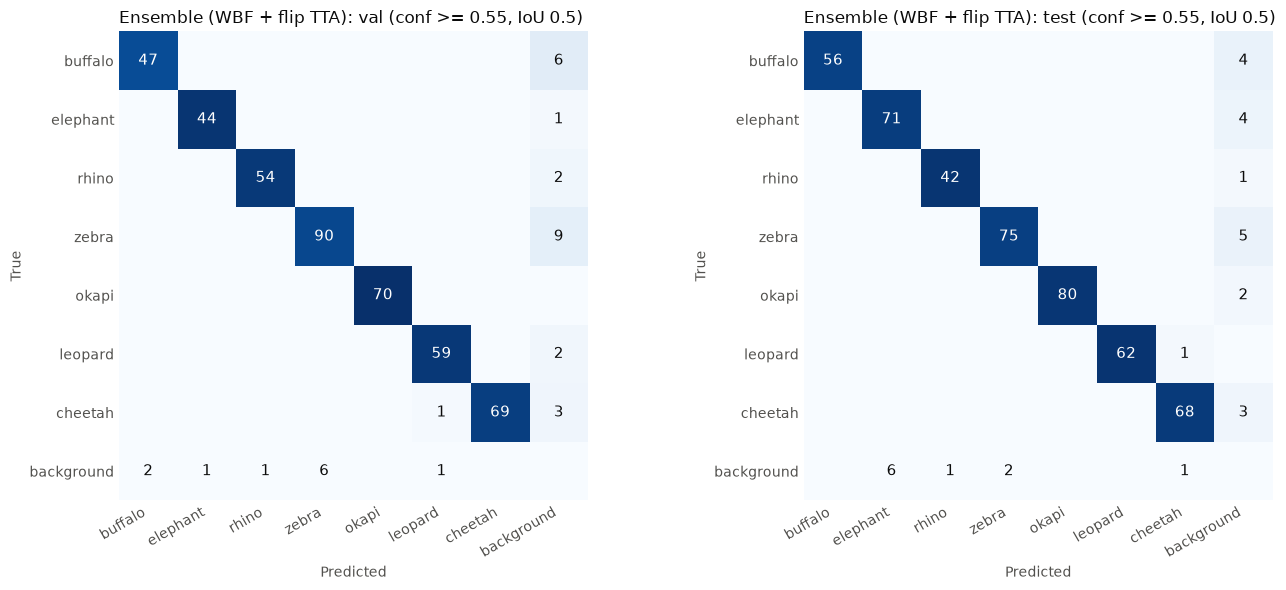

In [53]:
report_details(TTA_ENSEMBLE_NAME, 'ensemble_tta')

## Ensemble with flip TTA: agreement

How many of the predictions (each model on the original and on the mirrored image) contributed to each ensemble box that
passes the confidence cutoff.

In [ ]:
for split in SPLITS:
    conf_threshold = results[split][TTA_ENSEMBLE_NAME][0]['Best-F1 confidence']
    kept = np.concatenate([s[f.confidence >= conf_threshold]
                           for s, f in zip(ensemble_support[TTA_ENSEMBLE_NAME][split], predictions[split][TTA_ENSEMBLE_NAME])])
    boxes = pd.Series(kept).value_counts().sort_index(ascending=False)
    boxes.index = [f'Found by {k}/{2 * len(MODELS)} predictions' for k in boxes.index]
    agreement = pd.DataFrame({'Boxes': boxes, 'Share': boxes / max(len(kept), 1)})
    print(f'\n[{split}] conf >= {conf_threshold}')
    print(agreement.round(4).to_string())


[val] conf >= 0.55
                          Boxes   Share
Found by 8/8 predictions    444  0.9978
Found by 6/8 predictions      1  0.0022

[test] conf >= 0.55
                          Boxes   Share
Found by 8/8 predictions    463  0.9957
Found by 7/8 predictions      2  0.0043


: 